## Імпорт бібліотек і початкові налаштування ##

In [1]:

# Імпорт бібліотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sklearn
import json

from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# Початкове значення для відтворюваності результатів
SEED = 42
keras.utils.set_random_seed(SEED)

# Створення папки для збереження результатів
Path("artifacts").mkdir(parents=True, exist_ok=True)

# Перевірка версій бібліотек
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", plt.matplotlib.__version__)


TensorFlow: 2.21.0
NumPy: 2.5.3
Pandas: 3.0.6
Scikit-learn: 1.9.1
Matplotlib: 3.11.2


## Завантаження датасету ##

In [2]:

# Завантаження датасету Fashion-MNIST
(x_dev, y_dev), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Назви 10 класів у правильному порядку
class_names = ["Футболка або топ", "Штани", "Светр", "Сукня",
    "Пальто", "Сандалі", "Сорочка", "Кросівки", "Сумка", "Черевики"]

# Перевірка розмірів даних
print("Розмір x_dev:", x_dev.shape)
print("Розмір y_dev:", y_dev.shape)
print("Розмір x_test:", x_test.shape)
print("Розмір y_test:", y_test.shape)

# Перевірка типів даних
print("\nТип x_dev:", x_dev.dtype)
print("Тип y_dev:", y_dev.dtype)

# Мінімальне та максимальне значення пікселів
print("\nМінімальне значення пікселя:", x_dev.min())
print("Максимальне значення пікселя:", x_dev.max())

# Мінімальна та максимальна мітки класів
print("\nМінімальна мітка:", y_dev.min())
print("Максимальна мітка:", y_dev.max())

# Перевірка назв класів
print("\nКількість класів:", len(class_names))
for i, name in enumerate(class_names):
    print(i, "-", name)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 11s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 4s 1us/step
Розмір x_dev: (60000, 28, 28)
Розмір y_dev: (60000,)
Розмір x_test: (10000, 28, 28)
Розмір y_test: (10000,)

Тип x_dev: uint8
Тип y_dev: uint8

Мінімальне значення пікселя: 0
Максимальне значення пікселя: 255

Мінімальна мітка: 0
Максимальна мітка: 9

Кількість класів: 10
0 - Футболка або топ
1 - Штани
2 - Светр
3 - Сукня
4 - Пальто
5 - Сандалі
6 - Сорочка
7 - Кросівки
8 - Сумка
9 - Черевики


## Перевірка даних ##

In [3]:

# Перевірка пропущених і некоректних значень
print("Пропущені значення в x_dev:", np.isnan(x_dev).sum())
print("Пропущені значення в x_test:", np.isnan(x_test).sum())

print("Мітки y_dev у межах 0–9:",
      np.isin(y_dev, range(10)).all())

print("Мітки y_test у межах 0–9:",
      np.isin(y_test, range(10)).all())

# Перевірка форми зображень
assert x_dev.shape[1:] == (28, 28)
assert x_test.shape[1:] == (28, 28)

# Перевірка кількості міток
assert len(x_dev) == len(y_dev)
assert len(x_test) == len(y_test)

# Перевірка діапазону пікселів
assert x_dev.min() >= 0 and x_dev.max() <= 255
assert x_test.min() >= 0 and x_test.max() <= 255

print("\nПеревірки успішно пройдено!")


Пропущені значення в x_dev: 0
Пропущені значення в x_test: 0
Мітки y_dev у межах 0–9: True
Мітки y_test у межах 0–9: True

Перевірки успішно пройдено!


## Сітка з 10 зображень ##

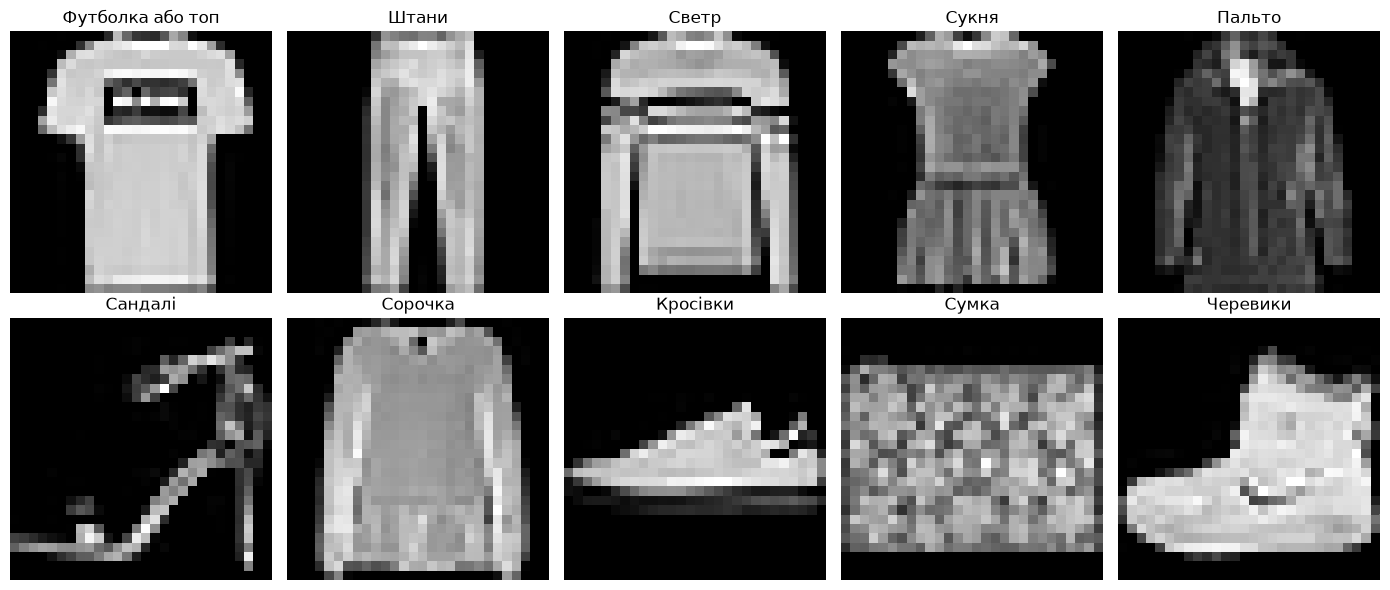

In [4]:

# Створення сітки з 10 зображень — по одному на клас
plt.figure(figsize=(14, 6))

for class_id in range(10):
    # Знаходимо перше зображення потрібного класу
    image_index = np.where(y_dev == class_id)[0][0]

    # Відображаємо зображення
    plt.subplot(2, 5, class_id + 1)
    plt.imshow(x_dev[image_index], cmap="gray")
    plt.title(class_names[class_id])
    plt.axis("off")

plt.tight_layout()
plt.show()


## Кількість зображень кожного класу ##

In [5]:

# Підрахунок кількості об'єктів кожного класу
class_counts = pd.Series(
    y_dev,
    name="Клас"
).value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Номер класу": range(10),
    "Назва класу": class_names,
    "Кількість зображень": class_counts.values
})

display(class_distribution)

print("\nЗагальна кількість зображень:", class_counts.sum())


,Номер класу,Назва класу,Кількість зображень
0,0,Футболка або топ,6000
1,1,Штани,6000
2,2,Светр,6000
3,3,Сукня,6000
4,4,Пальто,6000
5,5,Сандалі,6000
6,6,Сорочка,6000
7,7,Кросівки,6000
8,8,Сумка,6000
9,9,Черевики,6000



Загальна кількість зображень: 60000


## Поділ даних ##

In [6]:

# Поділ навчальних даних на train і validation
x_train, x_val, y_train, y_val = train_test_split(
    x_dev,
    y_dev,
    test_size=0.20,
    stratify=y_dev,
    random_state=SEED
)

# Перевірка розмірів вибірок
print("Train:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)


Train: (48000, 28, 28) (48000,)
Validation: (12000, 28, 28) (12000,)
Test: (10000, 28, 28) (10000,)


## Перевірка розподілу та індексів ##

In [7]:

# Перевірка кількості зображень
assert len(x_train) == 48000
assert len(x_val) == 12000
assert len(x_test) == 10000

# Перевірка кількості кожного класу
print("Кількість класів у train:",
      np.bincount(y_train, minlength=10))
print("Кількість класів у validation:",
      np.bincount(y_val, minlength=10))
print("Кількість класів у test:",
      np.bincount(y_test, minlength=10))

print("\nРозміри вибірок перевірено успішно!")


Кількість класів у train: [4800 4800 4800 4800 4800 4800 4800 4800 4800 4800]
Кількість класів у validation: [1200 1200 1200 1200 1200 1200 1200 1200 1200 1200]
Кількість класів у test: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]

Розміри вибірок перевірено успішно!


## Підготовка зображень ##

In [8]:

# Перетворення типу даних зображень
x_train = x_train.astype("float32")
x_val = x_val.astype("float32")
x_test = x_test.astype("float32")

# Перевірка підготовлених даних
assert x_train.shape[1:] == (28, 28)
assert np.isfinite(x_train).all()
assert set(np.unique(y_train)) == set(range(10))

print("Тип x_train:", x_train.dtype)
print("Діапазон пікселів:", x_train.min(), "-", x_train.max())
print("Форма train:", x_train.shape)
print("Підготовку даних завершено!")


Тип x_train: float32
Діапазон пікселів: 0.0 - 255.0
Форма train: (48000, 28, 28)
Підготовку даних завершено!


## Навчання DummyClassifier ##

In [9]:

# Перетворення зображень у вектори з 784 значень
X_train_flat = x_train.reshape(len(x_train), -1)
X_val_flat = x_val.reshape(len(x_val), -1)

# Створення та навчання простої базової моделі
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train_flat, y_train)

# Прогнозування класів на validation
dummy_val_pred = dummy_model.predict(X_val_flat)

# Оцінювання якості baseline
dummy_accuracy = accuracy_score(y_val, dummy_val_pred)
dummy_f1 = f1_score(
    y_val, dummy_val_pred,
    average="macro",
    zero_division=0
)

print("DummyClassifier")
print("Validation accuracy:", dummy_accuracy)
print("Validation macro-F1:", dummy_f1)


DummyClassifier
Validation accuracy: 0.1
Validation macro-F1: 0.01818181818181818


## Створення базової нейромережі ##

In [10]:

# Повторне встановлення seed перед створенням моделі
keras.utils.set_random_seed(SEED)

# Створення базової нейромережі
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Rescaling(1./255),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

# Налаштування навчання
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(name="accuracy")
    ]
)

# Перегляд архітектури моделі
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Навчання базової нейромережі ##

In [11]:

# Повторне встановлення seed перед навчанням
keras.utils.set_random_seed(SEED)

# Шлях до найкращої базової моделі
checkpoint_path = "artifacts/base_best.keras"

# Зворотні виклики для контролю навчання
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=4,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )
]

# Навчання базової нейромережі
history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=callbacks,
    verbose=0
)

# Завантаження найкращого checkpoint
best_model = keras.models.load_model(checkpoint_path)

# Виведення результатів навчання
print("Фактична кількість епох:", len(history.history["loss"]))
print("Найкраща епоха:",
      np.argmin(history.history["val_loss"]) + 1)
print("Найкращий val_loss:",
      min(history.history["val_loss"]))


Фактична кількість епох: 16
Найкраща епоха: 12
Найкращий val_loss: 0.3203228712081909


## Модель варіанта 10 — L2-регуляризація ##

In [12]:

# Встановлення seed перед створенням варіантної моделі
keras.utils.set_random_seed(SEED)

# Створення нейромережі з L2-регуляризацією
model_l2 = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Rescaling(1./255),
    layers.Flatten(),
    layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=keras.regularizers.l2(0.0001)
    ),
    layers.Dense(10, activation="softmax")
])

# Налаштування навчання
model_l2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(name="accuracy")
    ]
)

# Перегляд архітектури
model_l2.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Навчання моделі з L2 ##

In [13]:

# Шлях до найкращої моделі з L2
checkpoint_path_l2 = "artifacts/l2_best.keras"

# Зворотні виклики
callbacks_l2 = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=4,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        checkpoint_path_l2,
        monitor="val_loss",
        mode="min",
        save_best_only=True
    )
]

# Навчання варіантної моделі
history_l2 = model_l2.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=callbacks_l2,
    verbose=0
)

# Завантаження найкращої моделі
best_model_l2 = keras.models.load_model(checkpoint_path_l2)

# Результати навчання
print("Фактична кількість епох:", len(history_l2.history["loss"]))
print("Найкраща епоха:",
      np.argmin(history_l2.history["val_loss"]) + 1)
print("Найкращий val_loss:",
      min(history_l2.history["val_loss"]))


Фактична кількість епох: 21
Найкраща епоха: 17
Найкращий val_loss: 0.35087427496910095


## Графіки навчання моделей ##

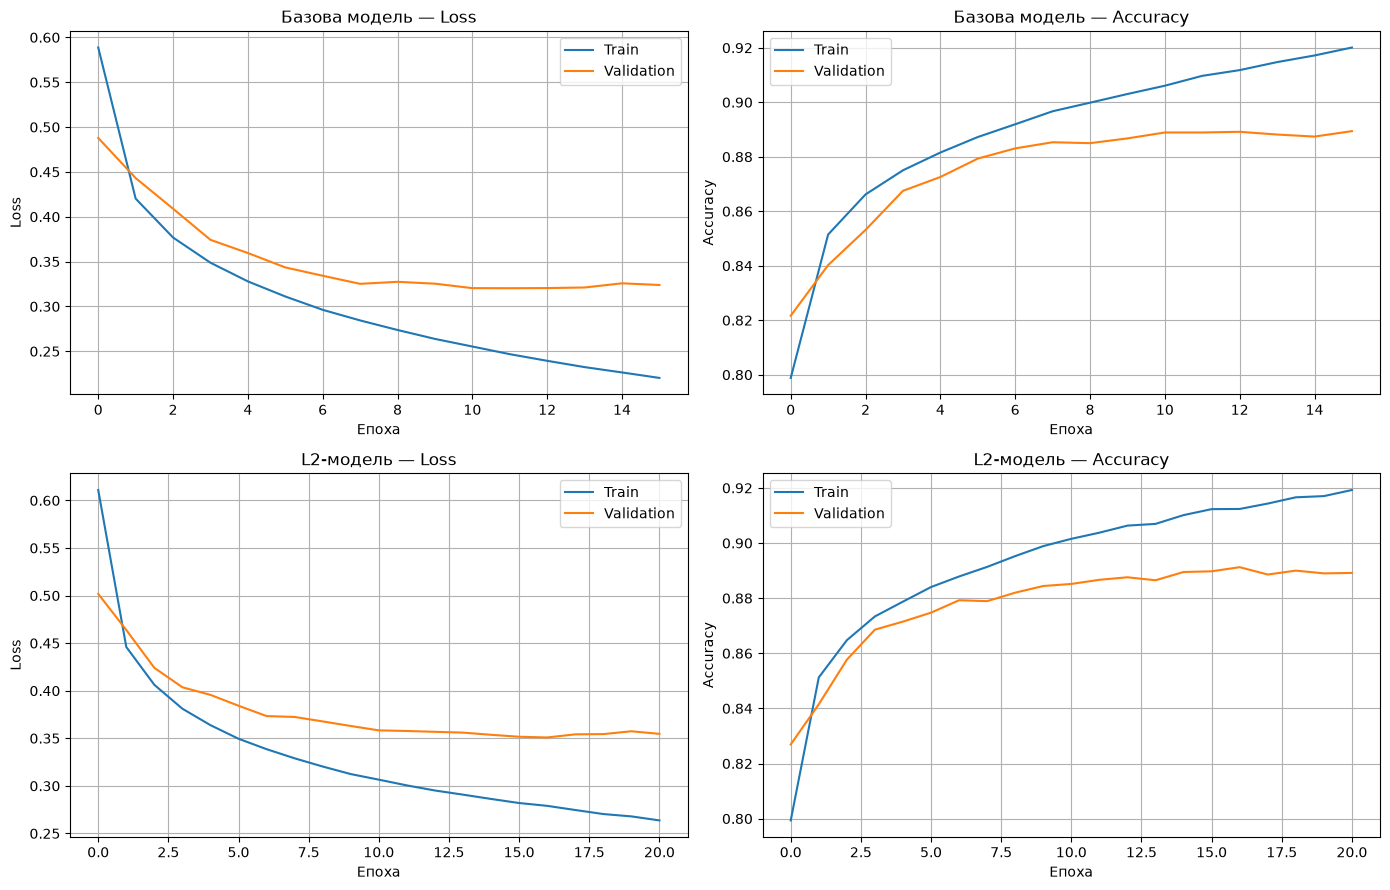

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Базова модель: функція втрат
axes[0, 0].plot(history.history["loss"], label="Train")
axes[0, 0].plot(history.history["val_loss"], label="Validation")
axes[0, 0].set_title("Базова модель — Loss")
axes[0, 0].set_xlabel("Епоха")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(True)

# Базова модель: точність
axes[0, 1].plot(history.history["accuracy"], label="Train")
axes[0, 1].plot(history.history["val_accuracy"], label="Validation")
axes[0, 1].set_title("Базова модель — Accuracy")
axes[0, 1].set_xlabel("Епоха")
axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].legend()
axes[0, 1].grid(True)

# Модель із L2-регуляризацією: функція втрат
axes[1, 0].plot(history_l2.history["loss"], label="Train")
axes[1, 0].plot(history_l2.history["val_loss"], label="Validation")
axes[1, 0].set_title("L2-модель — Loss")
axes[1, 0].set_xlabel("Епоха")
axes[1, 0].set_ylabel("Loss")
axes[1, 0].legend()
axes[1, 0].grid(True)

# Модель із L2-регуляризацією: точність
axes[1, 1].plot(history_l2.history["accuracy"], label="Train")
axes[1, 1].plot(history_l2.history["val_accuracy"], label="Validation")
axes[1, 1].set_title("L2-модель — Accuracy")
axes[1, 1].set_xlabel("Епоха")
axes[1, 1].set_ylabel("Accuracy")
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

## Порівняння моделей ##

In [15]:
# Отримуємо ймовірності для кожного класу
y_val_prob_base = best_model.predict(x_val, verbose=0)
y_val_prob_l2 = best_model_l2.predict(x_val, verbose=0)

# Перетворюємо ймовірності на номери класів
y_val_pred_base = np.argmax(y_val_prob_base, axis=1)
y_val_pred_l2 = np.argmax(y_val_prob_l2, axis=1)

# Формуємо таблицю результатів
results = pd.DataFrame([
    {
        "Модель": "DummyClassifier",
        "Accuracy": accuracy_score(y_val, dummy_val_pred),
        "Macro-F1": f1_score(
            y_val, dummy_val_pred, average="macro", zero_division=0
        )
    },
    {
        "Модель": "Базова нейромережа",
        "Accuracy": accuracy_score(y_val, y_val_pred_base),
        "Macro-F1": f1_score(
            y_val, y_val_pred_base, average="macro", zero_division=0
        )
    },
    {
        "Модель": "Нейромережа з L2",
        "Accuracy": accuracy_score(y_val, y_val_pred_l2),
        "Macro-F1": f1_score(
            y_val, y_val_pred_l2, average="macro", zero_division=0
        )
    }
])

display(results.round(4))

,Модель,Accuracy,Macro-F1
0,DummyClassifier,0.1000,0.0182
1,Базова нейромережа,0.8889,0.8898
2,Нейромережа з L2,0.8912,0.8917


## Обчислення чистої cross-entropy ##

In [16]:
# Обчислюємо cross-entropy без штрафу за регуляризацію
loss_fn = keras.losses.SparseCategoricalCrossentropy(
    from_logits=False
)

clean_loss_base = loss_fn(
    y_val, y_val_prob_base
).numpy()

clean_loss_l2 = loss_fn(
    y_val, y_val_prob_l2
).numpy()

print(f"Базова нейромережа — cross-entropy: {clean_loss_base:.4f}")
print(f"Нейромережа з L2 — cross-entropy: {clean_loss_l2:.4f}")

# Вибираємо модель за критерієм лабораторної
if clean_loss_l2 < clean_loss_base:
    selected_model = best_model_l2
    selected_name = "Нейромережа з L2"
    selected_prob = y_val_prob_l2
else:
    selected_model = best_model
    selected_name = "Базова нейромережа"
    selected_prob = y_val_prob_base

print("\nОбрана модель:", selected_name)
print("Причина: нижча чиста cross-entropy на валідаційних даних.")

Базова нейромережа — cross-entropy: 0.3197
Нейромережа з L2 — cross-entropy: 0.3106

Обрана модель: Нейромережа з L2
Причина: нижча чиста cross-entropy на валідаційних даних.


## Оцінювання моделей на тестовій вибірці ##

In [17]:
# Прогнози базової моделі та L2-моделі
y_test_prob_base = best_model.predict(x_test, verbose=0)
y_test_prob_l2 = best_model_l2.predict(x_test, verbose=0)

y_test_pred_base = np.argmax(y_test_prob_base, axis=1)
y_test_pred_l2 = np.argmax(y_test_prob_l2, axis=1)

# Прогнози DummyClassifier
X_test_flat = x_test.reshape(len(x_test), -1)
dummy_test_pred = dummy_model.predict(X_test_flat)

# Формуємо таблицю тестових результатів
test_results = pd.DataFrame([
    {
        "Модель": "DummyClassifier",
        "Accuracy": accuracy_score(y_test, dummy_test_pred),
        "Macro-F1": f1_score(
            y_test, dummy_test_pred, average="macro", zero_division=0
        )
    },
    {
        "Модель": "Базова нейромережа",
        "Accuracy": accuracy_score(y_test, y_test_pred_base),
        "Macro-F1": f1_score(
            y_test, y_test_pred_base, average="macro", zero_division=0
        )
    },
    {
        "Модель": "Нейромережа з L2",
        "Accuracy": accuracy_score(y_test, y_test_pred_l2),
        "Macro-F1": f1_score(
            y_test, y_test_pred_l2, average="macro", zero_division=0
        )
    }
])

display(test_results.round(4))

,Модель,Accuracy,Macro-F1
0,DummyClassifier,0.1000,0.0182
1,Базова нейромережа,0.8763,0.8771
2,Нейромережа з L2,0.8798,0.8803


## Матриця помилок ##

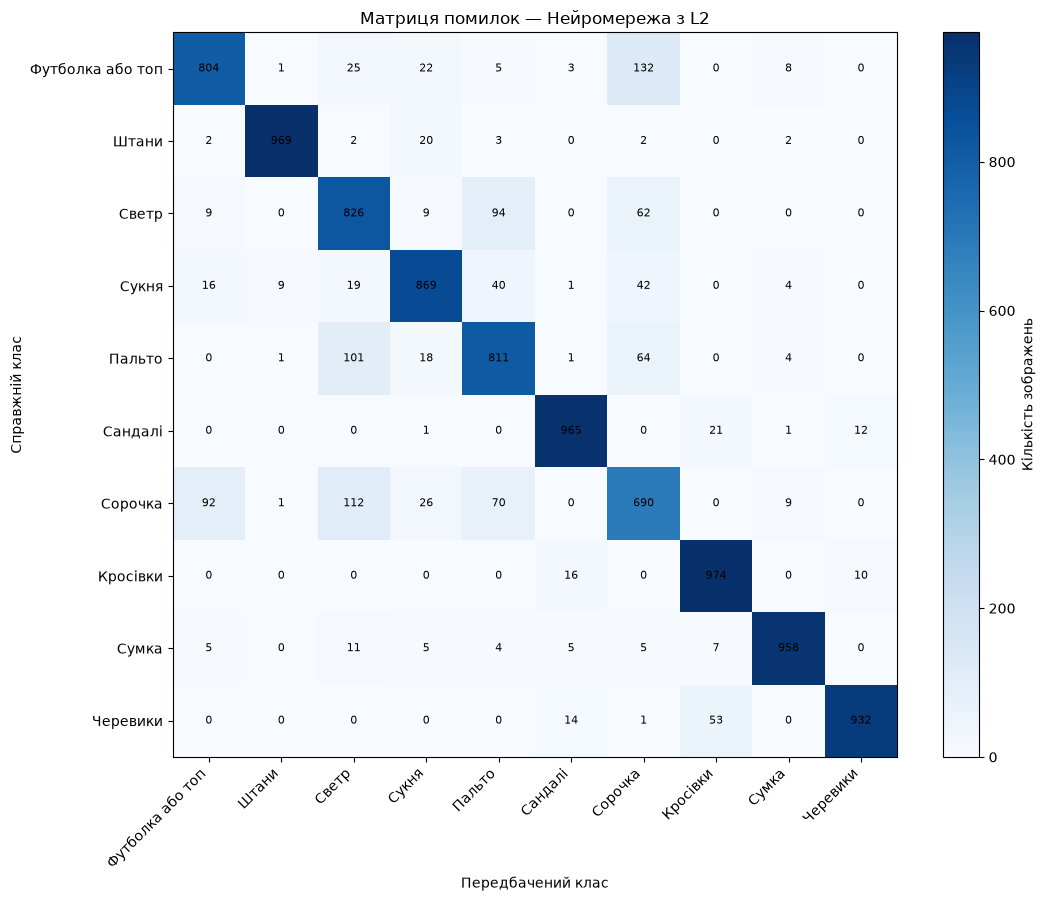

In [18]:
# Отримуємо прогнози обраної моделі на тестових даних
y_test_prob_selected = selected_model.predict(x_test, verbose=0)
y_test_pred_selected = np.argmax(y_test_prob_selected, axis=1)

# Обчислюємо матрицю помилок
cm = confusion_matrix(
    y_test,
    y_test_pred_selected,
    labels=np.arange(10)
)

# Візуалізуємо матрицю
plt.figure(figsize=(11, 9))
plt.imshow(cm, cmap="Blues")
plt.title(f"Матриця помилок — {selected_name}")
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")
plt.xticks(np.arange(10), class_names, rotation=45, ha="right")
plt.yticks(np.arange(10), class_names)
plt.colorbar(label="Кількість зображень")

# Підписуємо клітинки значеннями
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)

plt.tight_layout()
plt.show()

## Classification Report ##

In [19]:
report = classification_report(
    y_test,
    y_test_pred_selected,
    labels=np.arange(10),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

display(report_df.round(4))

,precision,recall,f1-score,support
Футболка або топ,0.8664,0.8040,0.8340,1000.0000
Штани,0.9878,0.9690,0.9783,1000.0000
Светр,0.7536,0.8260,0.7882,1000.0000
Сукня,0.8959,0.8690,0.8822,1000.0000
Пальто,0.7897,0.8110,0.8002,1000.0000
Сандалі,0.9602,0.9650,0.9626,1000.0000
Сорочка,0.6914,0.6900,0.6907,1000.0000
Кросівки,0.9232,0.9740,0.9479,1000.0000
Сумка,0.9716,0.9580,0.9648,1000.0000
Черевики,0.9769,0.9320,0.9539,1000.0000


## Найупевненіші помилки моделі ##

Кількість помилок: 1202
Індекс: 5946 | Справжній клас: Черевики | Прогноз: Сандалі | Упевненість: 99.99%
Індекс: 2599 | Справжній клас: Футболка або топ | Прогноз: Сумка | Упевненість: 99.96%
Індекс: 6565 | Справжній клас: Сумка | Прогноз: Кросівки | Упевненість: 99.96%
Індекс: 4040 | Справжній клас: Сандалі | Прогноз: Кросівки | Упевненість: 99.94%
Індекс: 7936 | Справжній клас: Черевики | Прогноз: Кросівки | Упевненість: 99.93%


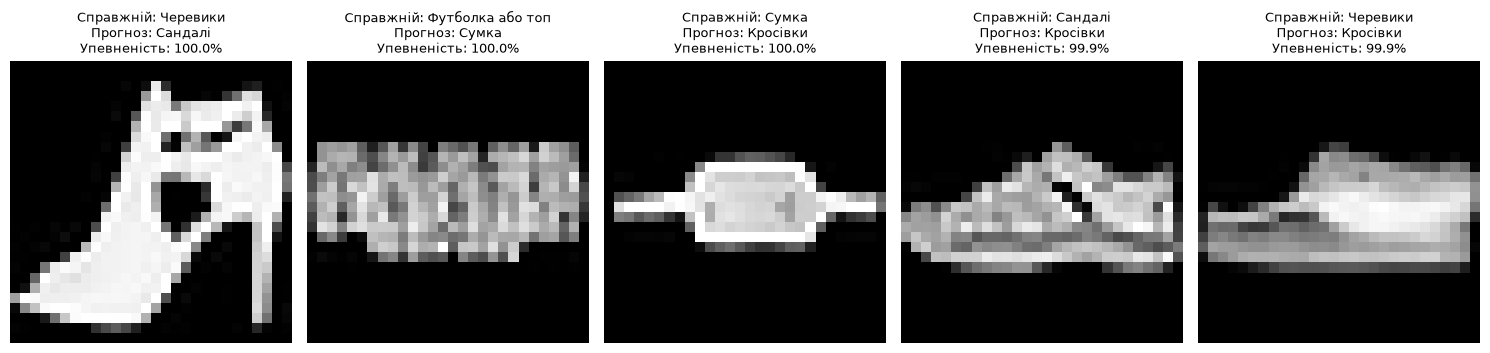

In [20]:
# Індекси зображень, які модель класифікувала неправильно
wrong_indices = np.where(y_test_pred_selected != y_test)[0]

# Упевненість моделі у передбаченому класі
confidences = np.max(y_test_prob_selected, axis=1)

# Сортуємо помилки від найвищої впевненості до найнижчої
sorted_wrong = wrong_indices[
    np.argsort(confidences[wrong_indices])[::-1]
]

# Беремо до 5 найупевненіших помилок
top_wrong = sorted_wrong[:5]

print("Кількість помилок:", len(wrong_indices))

for idx in top_wrong:
    print(
        f"Індекс: {idx} | "
        f"Справжній клас: {class_names[y_test[idx]]} | "
        f"Прогноз: {class_names[y_test_pred_selected[idx]]} | "
        f"Упевненість: {confidences[idx]:.2%}"
    )

# Візуалізуємо знайдені помилки
if len(top_wrong) > 0:
    fig, axes = plt.subplots(
        1, len(top_wrong),
        figsize=(3 * len(top_wrong), 4)
    )

    if len(top_wrong) == 1:
        axes = [axes]

    for ax, idx in zip(axes, top_wrong):
        ax.imshow(x_test[idx], cmap="gray")
        ax.set_title(
            f"Справжній: {class_names[y_test[idx]]}\n"
            f"Прогноз: {class_names[y_test_pred_selected[idx]]}\n"
            f"Упевненість: {confidences[idx]:.1%}",
            fontsize=9
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("На тестовій вибірці помилок немає.")

## Аналіз правильного та неправильного прогнозів ##

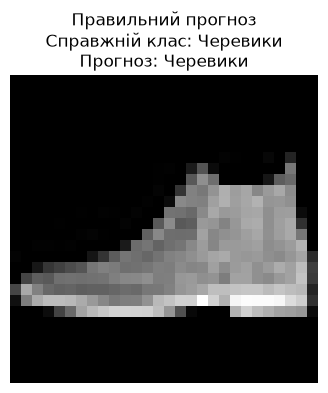

,Клас,Ймовірність
9,Черевики,91.58%
7,Кросівки,4.35%
5,Сандалі,4.05%
8,Сумка,0.01%
6,Сорочка,0.00%
2,Светр,0.00%
3,Сукня,0.00%
0,Футболка або топ,0.00%
4,Пальто,0.00%
1,Штани,0.00%


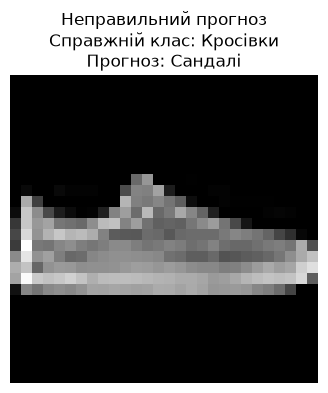

,Клас,Ймовірність
5,Сандалі,60.18%
7,Кросівки,29.76%
8,Сумка,10.03%
4,Пальто,0.02%
2,Светр,0.01%
9,Черевики,0.00%
0,Футболка або топ,0.00%
1,Штани,0.00%
6,Сорочка,0.00%
3,Сукня,0.00%


In [21]:
# Знаходимо індекси правильних і неправильних прогнозів
correct_indices = np.where(y_test_pred_selected == y_test)[0]
wrong_indices = np.where(y_test_pred_selected != y_test)[0]

# Обираємо по одному прикладу
correct_idx = correct_indices[0] if len(correct_indices) > 0 else None
wrong_idx = wrong_indices[0] if len(wrong_indices) > 0 else None

examples = []

if correct_idx is not None:
    examples.append(("Правильний прогноз", correct_idx))

if wrong_idx is not None:
    examples.append(("Неправильний прогноз", wrong_idx))

# Показуємо зображення та всі ймовірності
for title, idx in examples:
    probabilities = y_test_prob_selected[idx]

    plt.figure(figsize=(4, 4))
    plt.imshow(x_test[idx], cmap="gray")
    plt.title(
        f"{title}\n"
        f"Справжній клас: {class_names[y_test[idx]]}\n"
        f"Прогноз: {class_names[y_test_pred_selected[idx]]}"
    )
    plt.axis("off")
    plt.show()

    probability_table = pd.DataFrame({
        "Клас": class_names,
        "Ймовірність": probabilities
    }).sort_values("Ймовірність", ascending=False)

    display(probability_table.style.format({
        "Ймовірність": "{:.2%}"
    }))

## Збереження обраної моделі ##

In [22]:
# Зберігаємо обрану нейромережу
model_path = "artifacts/lab7_model.keras"
selected_model.save(model_path)

# Відновлюємо індекси train і validation
train_indices, val_indices = train_test_split(
    np.arange(len(y_dev)),
    test_size=0.20,
    stratify=y_dev,
    random_state=SEED
)

# Формуємо метадані моделі
metadata = {
    "model_name": selected_name,
    "variant": 10,
    "dataset": "Fashion-MNIST",
    "class_names": class_names,
    "input_shape": [28, 28],
    "input_dtype": "float32",
    "pixel_range_before_rescaling": [0, 255],
    "rescaling": "1./255",
    "rescaling_location": "inside_model",
    "seed": SEED,
    "train_size": len(x_train),
    "validation_size": len(x_val),
    "test_size": len(x_test),
    "split_indices": {
        "train": train_indices.tolist(),
        "validation": val_indices.tolist()
    },
    "selection_criterion": "Lowest clean validation cross-entropy; baseline wins ties",
    "clean_validation_cross_entropy": {
        "baseline": float(clean_loss_base),
        "l2": float(clean_loss_l2)
    },
    "versions": {
        "tensorflow": tf.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__
    }
}

# Записуємо метадані у JSON
metadata_path = "artifacts/lab7_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, ensure_ascii=False, indent=4)

print("Модель збережено:", model_path)
print("Метадані збережено:", metadata_path)
print("Обрана модель:", selected_name)

Модель збережено: artifacts/lab7_model.keras
Метадані збережено: artifacts/lab7_metadata.json
Обрана модель: Нейромережа з L2
